In [1]:
# Step 1: Import libraries and configure environment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import time

from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Project paths
PROCESSED_DIR = Path("../data/processed")
ARTIFACTS_DIR = Path("../artifacts")
MODEL_DIR = ARTIFACTS_DIR / "models"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PLOT_DIR = ARTIFACTS_DIR / "plots"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Device configuration
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Processed data directory:", PROCESSED_DIR.resolve())

Libraries imported successfully!
PyTorch version: 2.15.0
Device: mps
Processed data directory: /Users/shama/Documents/Predictive_Maintenance_RUL/data/processed


In [2]:
# Step 2: Load processed datasets

dataset_names = ["FD001", "FD002", "FD003", "FD004"]

processed_data = {}

for fd in dataset_names:

    file_path = PROCESSED_DIR / f"{fd}_processed.npz"

    data = np.load(file_path)

    processed_data[fd] = {
        "X_train": data["X_train"],
        "y_train": data["y_train"],
        "X_val": data["X_val"],
        "y_val": data["y_val"],
        "X_test": data["X_test"],
        "y_test": data["y_test"]
    }

    print(f"\n{fd}")
    print("Training:", processed_data[fd]["X_train"].shape)
    print("Validation:", processed_data[fd]["X_val"].shape)
    print("Test:", processed_data[fd]["X_test"].shape)


FD001
Training: (14241, 30, 18)
Validation: (3490, 30, 18)
Test: (100, 30, 18)

FD002
Training: (37432, 30, 24)
Validation: (8787, 30, 24)
Test: (259, 30, 24)

FD003
Training: (17692, 30, 19)
Validation: (4128, 30, 19)
Test: (100, 30, 19)

FD004
Training: (43523, 30, 24)
Validation: (10505, 30, 24)
Test: (248, 30, 24)


In [3]:
# Step 3: Create PyTorch DataLoaders

BATCH_SIZE = 128

data_loaders = {}

for fd, data in processed_data.items():

    # Convert training data to tensors
    X_train = torch.tensor(data["X_train"], dtype=torch.float32)
    y_train = torch.tensor(data["y_train"], dtype=torch.float32)

    # Convert validation data to tensors
    X_val = torch.tensor(data["X_val"], dtype=torch.float32)
    y_val = torch.tensor(data["y_val"], dtype=torch.float32)

    # Create TensorDatasets
    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)

    # Create DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    data_loaders[fd] = {
        "train": train_loader,
        "val": val_loader
    }

    print(f"\n{fd}")
    print("Training batches:", len(train_loader))
    print("Validation batches:", len(val_loader))


FD001
Training batches: 112
Validation batches: 28

FD002
Training batches: 293
Validation batches: 69

FD003
Training batches: 139
Validation batches: 33

FD004
Training batches: 341
Validation batches: 83


In [4]:
# Step 4: Define reusable BiLSTM model

class BiLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [5]:
# Step 5: Define reusable TCN model

class TCNBlock(nn.Module):

    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):

        super().__init__()

        padding = (kernel_size - 1) * dilation

        self.network = nn.Sequential(
            nn.Conv1d(
                in_channels,
                out_channels,
                kernel_size,
                padding=padding,
                dilation=dilation
            ),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                out_channels,
                out_channels,
                kernel_size,
                padding=padding,
                dilation=dilation
            ),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x):

        output = self.network(x)

        # Remove extra time steps introduced by padding
        output = output[:, :, :x.size(2)]

        residual = self.residual(x)

        return torch.relu(output + residual)


class TCN(nn.Module):

    def __init__(self, input_size, channels=64, dropout=0.2):

        super().__init__()

        self.blocks = nn.Sequential(
            TCNBlock(input_size, channels, 3, 1, dropout),
            TCNBlock(channels, channels, 3, 2, dropout),
            TCNBlock(channels, channels, 3, 4, dropout)
        )

        self.fc = nn.Sequential(
            nn.Linear(channels, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        # Convert (batch, time, features) to (batch, features, time)
        x = x.transpose(1, 2)

        output = self.blocks(x)

        last_output = output[:, :, -1]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [6]:
# Step 6: Define reusable Transformer model

class TransformerRUL(nn.Module):

    def __init__(
        self,
        input_size,
        d_model=32,
        num_heads=2,
        num_layers=1,
        dropout=0.26,
        window_size=30
    ):
        super().__init__()

        # Project sensor features into embedding dimension
        self.input_projection = nn.Linear(input_size, d_model)

        # Learnable positional encoding
        self.positional_encoding = nn.Parameter(
            torch.zeros(1, window_size, d_model)
        )

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=d_model * 2,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # RUL prediction head
        self.fc = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = x + self.positional_encoding

        output = self.transformer(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [7]:
# Step 7: Test all model architectures

model_classes = {
    "BiLSTM": BiLSTM,
    "TCN": TCN,
    "Transformer": TransformerRUL
}

for fd, data in processed_data.items():

    input_size = data["X_train"].shape[2]

    # Take a small sample batch
    sample = torch.tensor(
        data["X_train"][:8],
        dtype=torch.float32
    ).to(DEVICE)

    print(f"\n{fd} - Input shape: {sample.shape}")

    for model_name, model_class in model_classes.items():

        model = model_class(input_size=input_size).to(DEVICE)
        model.eval()

        with torch.no_grad():
            prediction = model(sample)

        print(
            f"{model_name} output shape: {prediction.shape}"
        )

        assert prediction.shape == (8,)

        del model, prediction

    del sample

print("\nAll three architectures passed shape testing!")


FD001 - Input shape: torch.Size([8, 30, 18])
BiLSTM output shape: torch.Size([8])
TCN output shape: torch.Size([8])
Transformer output shape: torch.Size([8])

FD002 - Input shape: torch.Size([8, 30, 24])
BiLSTM output shape: torch.Size([8])
TCN output shape: torch.Size([8])
Transformer output shape: torch.Size([8])

FD003 - Input shape: torch.Size([8, 30, 19])
BiLSTM output shape: torch.Size([8])
TCN output shape: torch.Size([8])
Transformer output shape: torch.Size([8])

FD004 - Input shape: torch.Size([8, 30, 24])
BiLSTM output shape: torch.Size([8])
TCN output shape: torch.Size([8])
Transformer output shape: torch.Size([8])

All three architectures passed shape testing!


In [8]:
# Step 8: Define reusable training function

def train_model(
    model,
    train_loader,
    val_loader,
    epochs=30,
    learning_rate=0.001,
    patience=5
):
    model = model.to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0
    patience_counter = 0

    start_time = time.time()

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):

        # Training
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(X_batch)

        train_loss /= len(train_loader.dataset)

        # Validation
        model.eval()
        val_loss = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)

                val_loss += loss.item() * len(X_batch)

        val_loss /= len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Save best weights
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            best_epoch = epoch + 1
            patience_counter = 0

        else:
            patience_counter += 1

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    # Restore best model
    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    return model, history, best_epoch, best_val_loss, training_time

In [9]:
# Step 9: Define validation metrics function

def calculate_metrics(model, val_loader):

    model.eval()

    actual_values = []
    predicted_values = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)

            predictions = model(X_batch)

            actual_values.extend(y_batch.numpy())
            predicted_values.extend(
                predictions.cpu().numpy()
            )

    actual_values = np.array(actual_values)
    predicted_values = np.array(predicted_values)

    mae = np.mean(
        np.abs(actual_values - predicted_values)
    )

    rmse = np.sqrt(
        np.mean((actual_values - predicted_values) ** 2)
    )

    return mae, rmse

In [10]:
# Step 10: Train all models across all datasets

all_results = []
trained_models = {}

for fd in processed_data:

    print(f"\n{'='*55}")
    print(f"TRAINING ON {fd}")
    print(f"{'='*55}")

    input_size = processed_data[fd]["X_train"].shape[2]

    trained_models[fd] = {}

    for model_name, model_class in model_classes.items():

        print(f"\nTraining {model_name} on {fd}...")

        # Initialize model
        model = model_class(input_size=input_size)

        # Train model
        model, history, best_epoch, best_val_loss, training_time = train_model(
            model,
            data_loaders[fd]["train"],
            data_loaders[fd]["val"],
            epochs=30,
            learning_rate=0.001,
            patience=5
        )

        # Calculate validation metrics
        mae, rmse = calculate_metrics(
            model,
            data_loaders[fd]["val"]
        )

        # Save model
        model_path = MODEL_DIR / f"{fd}_{model_name.lower()}.pth"
        torch.save(model.state_dict(), model_path)

        # Store trained model and history
        trained_models[fd][model_name] = {
            "model": model,
            "history": history
        }

        # Store results
        all_results.append({
            "Dataset": fd,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "Best_Epoch": best_epoch,
            "Best_Val_Loss": best_val_loss,
            "Training_Time": training_time
        })

        print(f"\n{model_name} - {fd} Results")
        print(f"MAE: {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"Best Epoch: {best_epoch}")
        print(f"Training Time: {training_time:.2f} seconds")

        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()

print("\nAll model training runs completed!")


TRAINING ON FD001

Training BiLSTM on FD001...
Epoch [1/30] Train Loss: 4671.9326 Val Loss: 999.1801
Epoch [2/30] Train Loss: 678.3390 Val Loss: 285.4727
Epoch [3/30] Train Loss: 383.4045 Val Loss: 206.8193
Epoch [4/30] Train Loss: 305.3001 Val Loss: 190.4552
Epoch [5/30] Train Loss: 250.4812 Val Loss: 196.4598
Epoch [6/30] Train Loss: 232.3500 Val Loss: 187.6223
Epoch [7/30] Train Loss: 221.9489 Val Loss: 196.6410
Epoch [8/30] Train Loss: 199.4161 Val Loss: 195.6447
Epoch [9/30] Train Loss: 194.3296 Val Loss: 168.5894
Epoch [10/30] Train Loss: 186.8012 Val Loss: 166.6791
Epoch [11/30] Train Loss: 174.4997 Val Loss: 185.5461
Epoch [12/30] Train Loss: 169.1009 Val Loss: 185.7782
Epoch [13/30] Train Loss: 160.4681 Val Loss: 180.0671
Epoch [14/30] Train Loss: 154.6919 Val Loss: 207.1094
Epoch [15/30] Train Loss: 143.4657 Val Loss: 194.7950
Early stopping triggered.

BiLSTM - FD001 Results
MAE: 9.0289
RMSE: 12.9104
Best Epoch: 10
Training Time: 47.64 seconds

Training TCN on FD001...
Epoc

In [11]:
# Step 11: Compare model performance

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=["Dataset", "MAE"]
).reset_index(drop=True)

display(
    results_df.round(4)
)

,Dataset,Model,MAE,RMSE,Best_Epoch,Best_Val_Loss,Training_Time
0,FD001,BiLSTM,9.0289,12.910400,10,166.6791,47.6385
1,FD001,Transformer,9.1828,12.459700,11,155.2432,23.8284
2,FD001,TCN,11.7008,14.998800,13,224.9625,39.1675
3,FD002,BiLSTM,12.8599,16.897400,8,285.5231,110.2159
4,FD002,Transformer,13.7825,18.796600,9,353.3137,50.1951
5,FD002,TCN,15.0980,19.287500,15,372.0090,120.3159
6,FD003,Transformer,7.5800,10.912900,19,119.0905,39.0557
7,FD003,BiLSTM,8.0933,12.055600,7,145.3365,47.1417
8,FD003,TCN,11.9874,16.111500,9,259.5802,37.6136
9,FD004,Transformer,14.9619,21.274099,8,452.5858,54.9584


In [12]:
# Step 13: Save multi-dataset model comparison

results_df.to_csv(
    METRICS_DIR / "multi_dataset_model_comparison.csv",
    index=False
)

best_models = (
    results_df.sort_values("MAE")
    .groupby("Dataset")
    .first()
    .reset_index()
)

print("BEST MODEL FOR EACH DATASET")
display(best_models.round(4))

print("\nResults saved successfully!")

BEST MODEL FOR EACH DATASET


,Dataset,Model,MAE,RMSE,Best_Epoch,Best_Val_Loss,Training_Time
0,FD001,BiLSTM,9.0289,12.910400,10,166.6791,47.6385
1,FD002,BiLSTM,12.8599,16.897400,8,285.5231,110.2159
2,FD003,Transformer,7.5800,10.912900,19,119.0905,39.0557
3,FD004,Transformer,14.9619,21.274099,8,452.5858,54.9584



Results saved successfully!


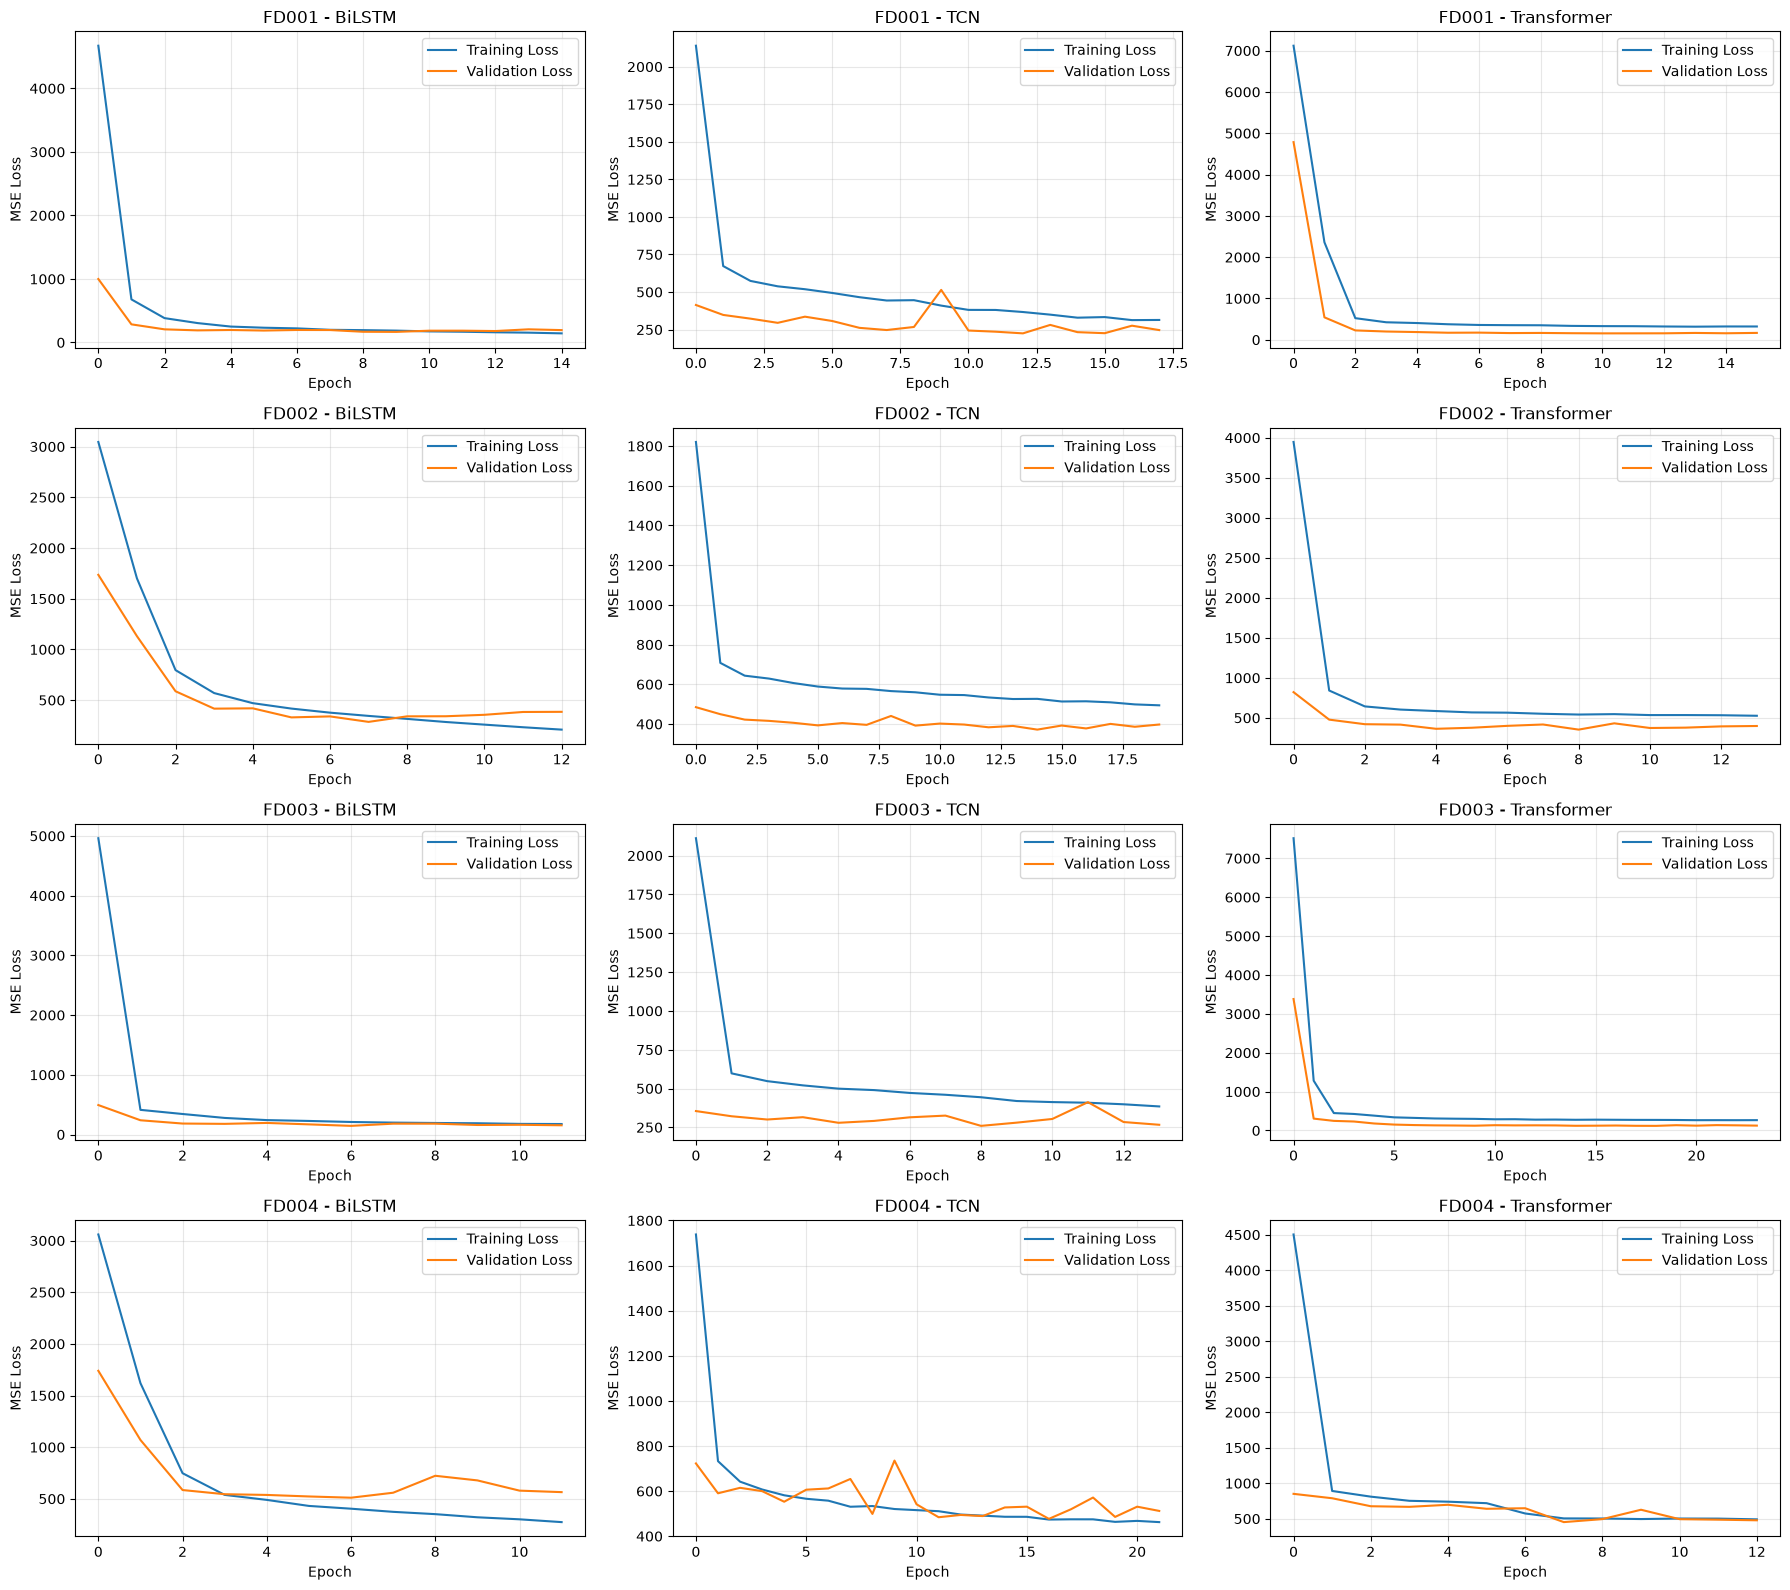

In [13]:
# Step 14: Plot training and validation loss curves

fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for i, fd in enumerate(processed_data):

    for j, model_name in enumerate(model_classes):

        history = trained_models[fd][model_name]["history"]

        axes[i, j].plot(
            history["train_loss"],
            label="Training Loss"
        )

        axes[i, j].plot(
            history["val_loss"],
            label="Validation Loss"
        )

        axes[i, j].set_title(f"{fd} - {model_name}")
        axes[i, j].set_xlabel("Epoch")
        axes[i, j].set_ylabel("MSE Loss")
        axes[i, j].legend()
        axes[i, j].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "multi_dataset_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

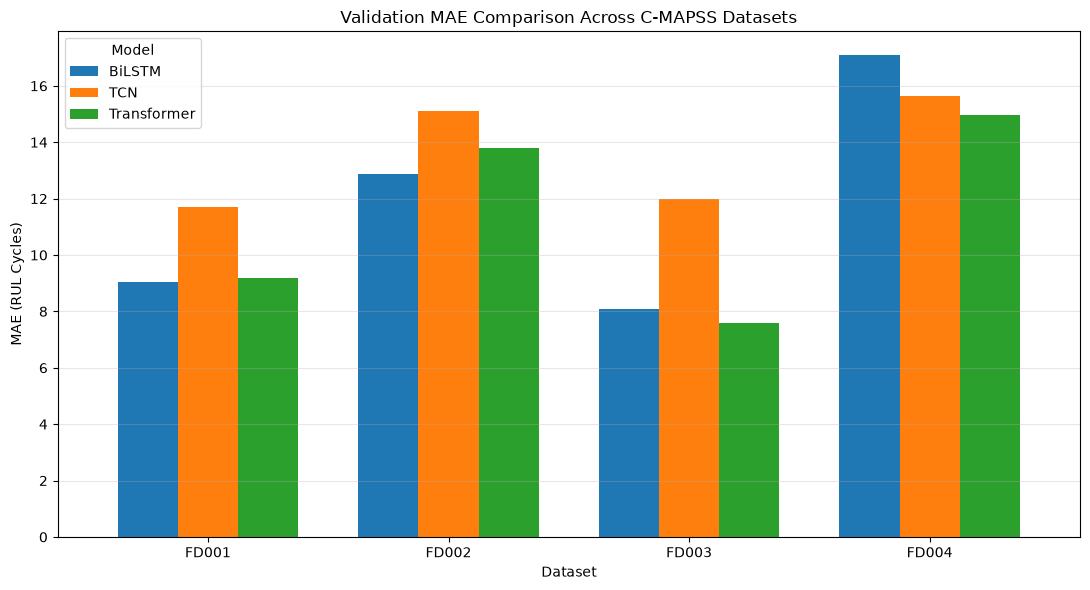

In [14]:
# Step 15: Compare validation MAE across datasets

mae_pivot = results_df.pivot(
    index="Dataset",
    columns="Model",
    values="MAE"
)

ax = mae_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Validation MAE Comparison Across C-MAPSS Datasets")
ax.set_xlabel("Dataset")
ax.set_ylabel("MAE (RUL Cycles)")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "multi_dataset_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Step 16: Save best model for each dataset

best_models.to_csv(
    METRICS_DIR / "best_models_by_dataset.csv",
    index=False
)

print("Best models saved successfully!")

display(
    best_models[["Dataset", "Model", "MAE", "RMSE"]]
)

Best models saved successfully!


,Dataset,Model,MAE,RMSE
0,FD001,BiLSTM,9.028864,12.910427
1,FD002,BiLSTM,12.859862,16.897429
2,FD003,Transformer,7.579959,10.912860
3,FD004,Transformer,14.961888,21.274063
